# Roteiro 5 - Agentes Lógicos
Este é o roteiro da quinta aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

Esse documento apresenta aplicações em `Python`utilizando os pacotes `experta` e `pyswip` (permite rodar códigos na linguagem `Prolog`).

Autor: Raoni F. S. Teixeira - raoni.teixeira@ufmt.br
___________________

# Experta

O [Experta](https://pypi.org/project/experta/) é um pacote Python que permite a criação de **motores de inferência** baseados em regras. Ele permite definir fatos (usando `Fact`), adcionar novos fatos à base de conhecimento (com `declare`) e criar regras (com `Rule`) para tomar decisões ou inferir conhecimento de forma declarativa e modular.




Antes de qualquer coisa, vamos instalar o `experta`


In [ ]:
! pip install experta # can't run with this package alone, compatibility issues experta 1.9.4 requires frozendict==1.2
! pip install --upgrade frozendict #yfinance 0.2.31 requires frozendict>=2.3.4
! pip uninstall frozendict
! pip uninstall yfinance
! pip install yfinance

  Preparing metadata (setup.py) ... done
  Created wheel for frozendict: filename=frozendict-1.2-py3-none-any.whl size=3149 sha256=502c0c330a15253b4729180c805374ac439066dd6ace919d0a148c12ce3139b2
  Stored in directory: /root/.cache/pip/wheels/49/ac/f8/cb8120244e710bdb479c86198b03c7b08c3c2d3d2bf448fd6e
Successfully built frozendict
  Attempting uninstall: frozendict
    Found existing installation: frozendict 2.4.6
    Uninstalling frozendict-2.4.6:
      Successfully uninstalled frozendict-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
yfinance 0.2.55 requires frozendict>=2.3.4, but you have frozendict 1.2 which is incompatible.
  Attempting uninstall: frozendict
    Found existing installation: frozendict 1.2
    Uninstalling frozendict-1.2:
      Successfully uninstalled frozendict-1.2
ERROR: pip's dependency resolver does not currently take into accou

In [ ]:
!pip install numpy

##Rule
`@Rule`define um gatilho para executar um bloco de código sempre que os fatos no sistema atenderem a uma determinada condição.

## Declare

A função `self.declare()` adiciona um novo fato à base de conhecimento do motor.

O código a seguir  um exemplo simples de como usar a biblioteca experta em Python para criar um sistema baseado em regras (também conhecido como sistema de produção).

In [ ]:
from experta import KnowledgeEngine, Rule, Fact

class MotorInferencia(KnowledgeEngine):
    @Rule(Fact(acao="andar"))
    def mover(self):
        print("O agente decidiu andar!")

# Criando e executando o motor
motor = MotorInferencia()
motor.reset()
motor.declare(Fact(acao="andar"))  # Declara um fato
motor.run()  # Roda o motor de inferência


O agente decidiu andar!


Nesse código,

- `KnowledgeEngine`: É a classe base fornecida pela biblioteca experta que permite criar um motor de inferência. Um motor de inferência é responsável por aplicar regras a fatos para chegar a conclusões.

- `Rule`: É um decorador que permite definir regras dentro do motor de inferência. As regras são condições que, quando atendidas, disparam ações específicas.

- `Fact`: Representa um fato, que é uma peça de informação que o motor de inferência usa para tomar decisões.

- `MotorInferencia`: Esta é uma classe que herda de `KnowledgeEngine`. Ela contém as regras que o motor de inferência usará para tomar decisões.

- `@Rule(Fact(acao="andar"))`: Este é um decorador que define uma regra. A regra especifica que, se um fato com o atributo acao igual a "andar" for declarado, a função mover será executada.

- `def mover(self)`: Esta é a função que será chamada quando a regra for ativada. Neste caso, ela simplesmente imprime uma mensagem indicando que o agente decidiu andar.


**Mas como esse código funciona?**

1. O motor começa vazio.
2. Declaramos um fato `Fact(acao="andar")`.
3. O motor executa `motor.run()`, que verifica todas as `@Rule`.
4. A regra `@Rule(Fact(acao="andar"))` é ativada porque o fato foi adicionado.
5. O código dentro da regra `mover()` é executado.

O código especifica **o que** deve ser feito, sem precisar detalher **como **executar as tarefas.


### Mundo de Wumpus

O [Mundo de Wumpus](https://en.wikipedia.org/wiki/Wumpus_world) é um jogo de aventura em um tabuleiro (matriz) bidimensional, geralmente representado como uma caverna com salas interconectadas. O agente (um personagem controlado por um programa de IA) deve explorar a caverna, coletar ouro e sair em segurança, evitando perigos mortais. O ambiente é composto por:

- **Wumpus**: Uma criatura perigosa que mata o agente se ele entrar na mesma sala.

- **Poços**: Buracos profundos que, se o agente cair, resultam em morte.

- **Ouro**: O objetivo principal do agente, que deve ser coletado e levado de volta à saída.

- **Brisas e Fedores**: Pistas sensoriais que indicam a proximidade de perigos.

- **Brisa**: Indica que há um poço em uma sala adjacente.

- **Fedor**: Indica que o Wumpus está em uma sala adjacente.

O agente começa em uma sala segura e deve explorar o ambiente com base nas percepções (brisas, fedores, brilho do ouro) para tomar decisões seguras e eficientes.

O código a seguir implementa em `Python` um agente para o Mundo de Wumpus que opera com base em regras e inferências. Ele usa um processo de raciocínio lógico para interpretar as percepções e tomar decisões. Por exemplo:

- Se o agente sentir um fedor, ele infere que o Wumpus está em uma célula adjacente.

- Se sentir uma brisa, ele sabe que há um poço próximo.

- Se não sentir nada, ele pode assumir que as salas adjacentes são seguras para explorar.



O código é uma tentativa de implementação de agente lógico para mundo de Wumpus em `experta`, organizado da seguinte forma:

### 1. **Classes e Estruturas Básicas**
   - **`Perception(Fact)`**: Esta classe representa as percepções do agente no mundo de Wumpus. Ela herda de `Fact`, que é uma classe base do módulo `experta` para representar fatos no sistema de regras.
   - **`Safe(Fact)`**: Esta classe representa as células que o agente considera seguras para se mover.

### 2. **Classe `WumpusWorld`**
   - **`__init__`**: O construtor inicializa o mundo de Wumpus. Ele define o tamanho do grid, a posição inicial do jogador, a posição do Wumpus, a posição do ouro e os buracos. Se `random=True`, as posições do Wumpus, do ouro e dos buracos são geradas aleatoriamente. Caso contrário, são usadas posições fixas.
   - **`adjacent_positions`**: Este método retorna as posições adjacentes à posição atual do jogador, considerando os limites do grid.

### 3. **Métodos de Inicialização e Exibição**
   - **`start`**: Inicializa o agente, exibe o tabuleiro, declara a posição inicial como segura e começa a inferência.
   - **`display_board`**: Exibe o tabuleiro atual, mostrando a posição do jogador (`P`), do Wumpus (`W`), do ouro (`G`) e dos buracos (`H`).

### 4. **Regras de Inferência**
   - **`move_prev_pos`**: Esta regra é ativada quando o agente percebe uma brisa ou fedor. Ela faz o agente se mover para uma posição segura anteriormente visitada.
   - **`mark_safe_cells`**: Esta regra é ativada quando não há brisa nem fedor. Ela marca as células adjacentes como seguras e decide o próximo movimento.

### 5. **Decisão de Movimento**
   - **`decide_move`**: Decide o próximo movimento do agente com base nas células seguras não visitadas. Se não houver células seguras não visitadas, o jogo termina.
   - **`execute_move`**: Executa o movimento para uma nova posição, atualiza o estado do jogo e verifica o ambiente.

### 6. **Verificações de Estado**
   - **`check_death`**: Verifica se o agente caiu em um buraco ou foi pego pelo Wumpus. Se sim, o jogo termina.
   - **`found_gold`**: Verifica se o agente encontrou o ouro. Se sim, o jogo termina com vitória.
   - **`check_environment`**: Verifica o ambiente atual, atualiza as percepções do agente e declara essas percepções no sistema de regras.


### Resumo do Funcionamento
1. O agente começa na posição (0, 0) e explora o Tabuleiro.
2. Ele recebe percepções (`brisa`, `fedor`) que indicam perigos próximos.
3. Com base nessas percepções, o agente decide se deve se mover para uma posição segura ou marcar células adjacentes como seguras. O agente analisa trata apenas o caso em que não há nem `brisa` nem `fedor`.
4. O agente continua explorando até encontrar o ouro, cair em um buraco ou ser pego pelo Wumpus.



In [ ]:
from experta import KnowledgeEngine, Fact, Rule, AS, OR, NOT
import random

class Perception(Fact):
    pass

class Safe(Fact):
    pass

class WumpusWorld(KnowledgeEngine):

    def __init__(self, grid_size=4, random=True):

        super().__init__()
        self.visited = set()
        self.grid_size = grid_size
        self.player_pos = (0, 0)
        self.possible_W = set()
        self.possible_H = set()

        if random:
            self.wumpus_pos = (random.randint(1, grid_size-1), random.randint(1, grid_size-1))
            self.gold_pos = (random.randint(0, grid_size-1), random.randint(0, grid_size-1))

            while self.gold_pos == self.wumpus_pos:
                self.gold_pos = (random.randint(0, grid_size-1), random.randint(0, grid_size-1))

            self.holes = set()
            for _ in range(random.randint(1, grid_size-1)):
                hole_pos = (random.randint(0, grid_size-1), random.randint(0, grid_size-1))
                if hole_pos not in {self.wumpus_pos, self.gold_pos, self.player_pos}:
                    self.holes.add(hole_pos)
        else:

            '''self.gold_pos = (1, 1)
            self.wumpus_pos = (3, 1)
            self.holes = {(2, 2), (2, 3)}'''
            self.gold_pos = (2, 1)
            self.wumpus_pos = (2, 0)
            self.holes = {(0, 2), (2, 2)}


    def adjacent_positions(self):
        return [
            (self.player_pos[0] + dx, self.player_pos[1] + dy)
            for dx, dy in [(-1,0), (1,0), (0,-1), (0,1)]
            if 0 <= self.player_pos[0] + dx < self.grid_size and 0 <= self.player_pos[1] + dy < self.grid_size
        ]

    def start(self):
        """Inicializa o agente e ativa a inferência."""
        self.display_board()
        self.declare(Safe(pos=self.player_pos))
        self.check_environment()
        self.run()

    def display_board(self):
        """Exibe o tabuleiro."""
        board = [['.' for _ in range(self.grid_size)] for _ in range(self.grid_size)]
        board[self.gold_pos[1]][self.gold_pos[0]] = 'G'
        board[self.wumpus_pos[1]][self.wumpus_pos[0]] = 'W'
        for hole in self.holes:
            board[hole[1]][hole[0]] = 'H'
        board[self.player_pos[1]][self.player_pos[0]] = 'P'
        print("\n".join(" ".join(row) for row in board))
        print()

    '''@Rule(AS.p << Perception(brisa=True) | AS.p << Perception(fedor=True))
    def move_prev_pos(self, p):
        """Se encontrar perigo, vai para outra posicao do segura."""
        self.retract(p)
        print("Há brisa ou fedor.")
        self.visited.add(self.player_pos)
        self.decide_move()'''

    @Rule(AS.p << Perception(brisa=False, fedor=False))
    def mark_safe_cells(self, p):
        """Marca células seguras ao redor do jogador se não houver perigo."""
        print("Não há brisa nem fedor. Marcando células adjacentes como seguras.")
        self.retract(p)
        self.visited.add(self.player_pos)

        for pos in self.adjacent_positions():
            self.declare(Safe(pos=pos))
            print(f"Célula {pos} marcada como segura.")

        self.decide_move()

    @Rule(AS.p << Perception(brisa=True, fedor=False))
    def avoid_hole(self, p):
        """Se há brisa, um buraco está próximo. Evita as células ao redor."""
        print("Há brisa! Um buraco está por perto. Evitando células perigosas.")
        self.retract(p)
        self.visited.add(self.player_pos)

        for pos in self.adjacent_positions():
            if pos not in self.visited:
                if pos in self.possible_W:  # Se já era possível Wumpus, agora sabemos que é segura!
                    print(f"{pos} era possível Wumpus e possível Buraco, então agora é segura!")
                    self.declare(Safe(pos=pos))
                else:
                    self.possible_H.add(pos)
                    print(f"Marcando {pos} como possível buraco.")

        self.decide_move()


    @Rule(AS.p << Perception(brisa=False, fedor=True))
    def avoid_wumpus(self, p):
        """Se há fedor, o Wumpus está próximo. Evita as células ao redor."""
        print("Há fedor! O Wumpus está por perto. Evitando possíveis posições do Wumpus.")
        self.retract(p)
        self.visited.add(self.player_pos)

        for pos in self.adjacent_positions():
            if pos not in self.visited:
                if pos in self.possible_H:  # Se já era possível Buraco, agora sabemos que é segura!
                    print(f"{pos} era possível Wumpus e possível Buraco, então agora é segura!")
                    self.declare(Safe(pos=pos))
                else:
                    self.possible_W.add(pos)
                    print(f"Marcando {pos} como possível Wumpus.")

        self.decide_move()

    '''@Rule(AS.p << Perception(possible_W=True, possible_H=True)) #enrtender como fazer funcionar
    def mark_safe_cells(self, p):
        """Marca células seguras ao redor do jogador se não houver perigo."""
        print("Não há brisa nem fedor. Marcando células adjacentes como seguras.")
        self.retract(p)
        self.visited.add(self.player_pos)

        for pos in self.adjacent_positions():
            self.declare(Safe(pos=pos))
            print(f"Célula {pos} marcada como segura.")

        self.decide_move()'''

    def decide_move(self):
        """Decide o próximo movimento."""
        print("Procurando movimento")

        safe_cells = {fact["pos"] for fact_id, fact in self.facts.items() if isinstance(fact, Safe)}
        unvisited_safe_cells = [cell for cell in safe_cells if cell not in self.visited]

        print("Celulas nao visitadas: ", unvisited_safe_cells)

        if unvisited_safe_cells:
            move = random.choice(unvisited_safe_cells)
        else:
            print("O agente está preso e não pode se mover. Fim de jogo.")
            exit()

        self.execute_move(move)

    def execute_move(self, new_pos):
        """Executa o movimento e atualiza o ambiente."""
        self.visited.add(self.player_pos)
        self.player_pos = new_pos

        print(f"Agente moveu para {self.player_pos}")
        self.display_board()

        self.check_environment()

        self.run()

    def check_death(self):
        """Verifica se o agente caiu em um buraco ou foi pego pelo Wumpus."""

        if self.player_pos in self.holes:
            print("O agente caiu em um buraco! Fim de jogo.")
            exit()
        if self.player_pos == self.wumpus_pos:
            print("O agente foi pego pelo Wumpus! Fim de jogo.")
            exit()

    def found_gold(self):
        """Verifica se o agente encontrou o ouro"""
        if self.player_pos == self.gold_pos:
            print("O agente encontrou o ouro! Fim de jogo!")
            exit()

    def check_environment(self):
        """Verifica o ambiente e atualiza percepções."""
        print("Verificando o ambiente...")

        self.found_gold()

        self.check_death()

        adjacent_positions = self.adjacent_positions()

        brisa = any(pos in self.holes for pos in adjacent_positions)
        fedor = any(pos == self.wumpus_pos for pos in adjacent_positions)
        brilho = self.player_pos == self.gold_pos

        print("Declarando as percepcoes ", brisa, fedor, brilho)
        self.declare(Perception(brisa=brisa, fedor=fedor, brilho=brilho))



# Inicializa o motor
try:
    engine = WumpusWorld(random=False)
    engine.reset()
    engine.start()
except:
    print("FIM")

P . W .
. . G .
H . H .
. . . .

Verificando o ambiente...
Declarando as percepcoes  False False False
Não há brisa nem fedor. Marcando células adjacentes como seguras.
Célula (1, 0) marcada como segura.
Célula (0, 1) marcada como segura.
Procurando movimento
Celulas nao visitadas:  [(1, 0), (0, 1)]
Agente moveu para (0, 1)
. . W .
P . G .
H . H .
. . . .

Verificando o ambiente...
Declarando as percepcoes  True False False
Há brisa! Um buraco está por perto. Evitando células perigosas.
Marcando (1, 1) como possível buraco.
Marcando (0, 2) como possível buraco.
Procurando movimento
Celulas nao visitadas:  [(1, 0)]
Agente moveu para (1, 0)
. P W .
. . G .
H . H .
. . . .

Verificando o ambiente...
Declarando as percepcoes  False True False
Há fedor! O Wumpus está por perto. Evitando possíveis posições do Wumpus.
Marcando (2, 0) como possível Wumpus.
(1, 1) era possível Wumpus e possível Buraco, então agora é segura!
Procurando movimento
Celulas nao visitadas:  [(1, 1)]
Agente moveu para

# Exercício (1.0 ponto)

O código acima não implementa funções para lidar com **Wumpus** e com **buracos**.
 Ele apenas evita células com fedor (indicando a proximidade do Wumpus) e com brisa (indicando a proximidade de buracos) e não implementa  uma estratégia para contornar o Wumpus e buracos  de forma eficiente.

 Por isso, o agente não consegue encontrar o ouro no Tabuleiro mesmo com um caminho seguro entre o agente e o ouro:

    P . W .
    . . G .
    H . H .
    . . . .

Implemente funções para contornar o **Wumpus** e **buracos** e encontrar o ouro nesse Tabuleiro.

Você deve implementar funções para as regras:
- `@Rule(AS.p << Perception(brisa=True, fedor=False))` e
- `@Rule(AS.p << Perception(brisa=False, fedor=True))`.

# Prolog

[Prolog](https://pt.wikipedia.org/wiki/Prolog) é uma linguagem de **programação lógica**. Isso significa que sua natureza é diferente de linguagens de propósito geral, como C++, Java, Python, JavaScript, entre outras.

Prolog é baseado na [Lógica de Primeira Ordem](https://en.wikipedia.org/wiki/First-order_logic) e foi projetado para ser uma [linguagem de programação declarativa](https://en.wikipedia.org/wiki/Declarative_programming). Nela, a lógica é expressa por meio de relações, e os cálculos são iniciados por consultas.

A linguagem é usada em provas de teoremas, criação de sistemas especializados, reescrita de termos, planejamento automatizado, [processamento de linguagem natural (PLN)](https://en.wikipedia.org/wiki/Natural_language_processing) e muitas outras áreas interessantes.

---


## Instalação

Prolog é uma linguagem padronizada, com diversas implementações disponíveis. A mais conhecida e utilizada é o SWI-Prolog. Você pode baixar o instalador do SWI-Prolog diretamente do site oficial:  
[Download do SWI-Prolog](https://www.swi-prolog.org/download/stable).

Se você usa Windows, **marque a opção 'adicionar swipl ao PATH do sistema para todos os usuários'** durante a instalação. Caso esqueça, é possível adicionar manualmente o caminho `C:\Program Files\swipl\bin` ao PATH do sistema, desde que você tenha usado o diretório de instalação padrão.

Para utilizar o notebook colab,  vamos utilizar o pacote `pyswip` que roda o código usando SWI-Prolog. Você pode encontrar um tutorial de instalação  [aqui](https://github.com/yuce/pyswip/blob/master/INSTALL.md).


In [ ]:
!pip install pyswip
!apt install swi-prolog-nox


## Carregando pacote pyswip

In [ ]:
from pyswip import Prolog, registerForeign
prolog = Prolog()

## Hello World

Como em todos os tutoriais de linguagens de programação, o primeiro exemplo é o "Hello World"!

```prolog
write('Hello World'), nl, write('Let\'s Learn Prolog!').
```

Observe que todas as instruções em Prolog devem terminar com um ponto final `.`.

Como estamos usando o pyswip aqui, não precisaremos da função `write` do Prolog, pois podemos usar o `print` do Python e até mesmo algumas funções do Python.

---


### Terminologias

- **Fato**: Um fato é uma expressão de predicado que faz uma declaração sobre o domínio do problema. Os fatos consistem em um item específico ou em uma relação entre itens.

```prolog
rainy.

father(michael, jane).
```

Essas duas declarações são fatos. `father` é uma relação. `rainy`, `michael` e `jane` são *átomos* (constantes). Todos os *átomos* devem começar com letras **minúsculas**, a menos que estejam entre aspas simples `'`.

- **Regras**: As regras permitem fazer declarações condicionais. Elas são definidas usando o símbolo `:-`. `esquerda :- direita1, direita2` significa que **SE** `direita1` **e** `direita2` forem verdadeiros, então `esquerda` também será verdadeiro. Observe que `,` atua como operador *e*, enquanto `;` atua como operador *ou*.

- **Variáveis**: Uma variável é um objeto cujo nome não pode ser determinado no momento da execução. As variáveis são escritas com **letras maiúsculas**.

- **Consulta**: Ao fazer uma consulta, você pergunta ao Prolog se ele pode *provar* que sua afirmação é verdadeira. No Prolog, uma consulta é feita com o símbolo `?-`, mas no `pyswip` podemos usar `query(string)`.

<div><a class="anchor" id="simple-example"></a></div>

### Exemplo simples  
Vamos ver um exemplo simples:

In [ ]:
prolog.assertz("father(raoni,heloisa)")
prolog.assertz("child(X,Y) :- father(Y,X)")

In [ ]:
for solns in prolog.query("child(X , Y)"): #X and Y are prolog variables. This two lines simply print all child relationships.
    print(solns["X"] , "is child of" , solns["Y"])

heloisa is child of raoni


A primeira linha é um *fato* que afirma que Michael é o pai de Jane. A segunda linha é uma *regra* que diz: se Y é o pai de X, então X é filho de Y. Note que X e Y são variáveis.  

No `for`, fazemos uma *consulta* para todas as relações `child` e as exibimos. O resultado de `query()` é um gerador do Python e deve ser usado em um loop `for` ou convertido em uma `list`.

## Exemplo dois

 Você pode carregar um banco de dados de instruções em Prolog usando `consult`. Essa função funciona tanto no Prolog quanto no pyswip. No Prolog, você pode usar tanto `?- consult('arquivo.pl').` quanto `['arquivo1.pl'].`. No pyswip, você pode usar a função `consult(caminho)`.



Considere o arquivo abaixo com uma sequência de predicados.
```prolog
% 1.pl

father(albert, bob).
father(albert, betsy).
father(albert, bill).

mother(alice, bob).
mother(alice, betsy).
mother(alice, bill).

father(bob, carl).
father(bob, charlie).

parent(X,Y) :- father(X,Y); mother(X,Y).

grandparent(X,Y) :- parent(X,Z),parent(Z,Y). %X is grandparent of Y if X is parent of Z and Z is parent of Y

grandchild(X,Y) :- parent(Z,X) , parent(Y,Z). %X is grandchild of Y if Y is parent of Z and Z is parent of X
```

In [ ]:
# Baixe o arquivo
!gdown 13twJ56qIGjq9_-jNGxw6nAnTkhHsqWZ2

Downloading...
From (original): https://drive.google.com/uc?id=13twJ56qIGjq9_-jNGxw6nAnTkhHsqWZ2
From (redirected): https://drive.google.com/uc?id=13twJ56qIGjq9_-jNGxw6nAnTkhHsqWZ2&confirm=t&uuid=a6e4e66a-453f-4957-8e2f-6ea512471d5b
To: /content/1.pl
100% 460/460 [00:00<00:00, 2.12MB/s]


In [ ]:
prolog.consult("1.pl")

In [ ]:
for solns in prolog.query("grandparent(albert , X)"):
    print("Albert" , "is grandparent of" , solns["X"])
for solns in prolog.query("grandchild(carl , X)"):
    print("Albert" , "is grandchild of" , solns["X"])

## Outros exemplos



### Torre de Hanoi

A Torre de Hanói é um problema de programação muito famoso, frequentemente usado para ensinar funções recursivas. Você pode conferir a definição do problema na Wikipedia.

O código abaixo é uma implementação em Prolog do arquivo `hanoi.pl`.

```prolog
% hanoi.pl

hanoi(N) :- move(N, left, right, center).
move(0, _, _, _) :- !.
move(N, A, B, C) :-
  M is N-1,
  move(M, A, C, B),
  notify([A,B]),
  move(M, C, B, A).
```

In [ ]:
# Baixe o arquivo
!gdown 12u7jWcy7PxNzGWw-P-q318uYSQSl0s_C

In [ ]:
prolog.consult("hanoi.pl")

In [ ]:
N= 3

def notify(t):
        print("move disk from %s pole to %s pole." % tuple(t))
notify.arity = 1

registerForeign(notify)
list(prolog.query("hanoi(%d)" % N));

## $N$-Damas

O [problema das $N$-Damas](https://en.wikipedia.org/wiki/Eight_queens_puzzle) é um desafio famoso que consiste em posicionar $N$ damas em um tabuleiro de xadrez $N \times N$ de forma que nenhuma delas se ataque.

Como estudamos na [aula 3](https://colab.research.google.com/drive/1soPweeyTGDcvZcb8mu074Tu-SYCeLXMh?usp=sharing), em cada coluna deve haver exatamente uma rainha. Por isso, codificamos o estado como um vetor cujo elemento na posição $i$ indica em qual coluna a dama da linha $i$ está posicionada.

Podemos modelar esse problema em Prolog da seguinte forma:



```
% Predicado principal para resolver o problema das N-Rainhas
n_rainhas(N, Solucao) :-
    length(Solucao, N),              % Solucao é uma lista de tamanho N
    coloca_rainhas(Solucao, N).      % Posiciona as rainhas de forma válida

% Predicado para colocar rainhas no tabuleiro
coloca_rainhas([], _).
coloca_rainhas([Q|OutrasRainhas], N) :-
    coloca_rainhas(OutrasRainhas, N), % Resolve recursivamente para outras rainhas
    between(1, N, Q),                 % Escolhe uma posição válida na coluna
    seguro(Q, OutrasRainhas, 1).      % Garante que a posição é segura

% Verifica se uma rainha está segura (não é atacada por outras)
seguro(_, [], _).
seguro(Q, [Q1|Outras], Dist) :-
    Q =\= Q1,                     % Não está na mesma linha
    abs(Q - Q1) =\= Dist,         % Não está na mesma diagonal
    Dist1 is Dist + 1,
    seguro(Q, Outras, Dist1).

% Executar a consulta:
% ?- n_rainhas(4, Solucao).
% Solucao = [2, 4, 1, 3] ; % Uma solução possível para 4x4
```





In [ ]:
# Baixe o arquivo
!gdown 1c_Zy5kBkSj0JhGhwDtHtJqdwCBMSROzh

Downloading...
From (original): https://drive.google.com/uc?id=1c_Zy5kBkSj0JhGhwDtHtJqdwCBMSROzh
From (redirected): https://drive.google.com/uc?id=1c_Zy5kBkSj0JhGhwDtHtJqdwCBMSROzh&confirm=t&uuid=dd5d8a11-b2ce-411c-9288-d0c75b9fa05e
To: /content/damas.pl
100% 1.03k/1.03k [00:00<00:00, 4.97MB/s]


In [ ]:
prolog.consult("damas.pl")

In [ ]:
for i,soln in enumerate(prolog.query("n_rainhas(%d, Qs)." % (8))):
    print(i+1,".\t",soln["Qs"])


1 .	 [4, 2, 7, 3, 6, 8, 5, 1]
2 .	 [5, 2, 4, 7, 3, 8, 6, 1]
3 .	 [3, 5, 2, 8, 6, 4, 7, 1]
4 .	 [3, 6, 4, 2, 8, 5, 7, 1]
5 .	 [5, 7, 1, 3, 8, 6, 4, 2]
6 .	 [4, 6, 8, 3, 1, 7, 5, 2]
7 .	 [3, 6, 8, 1, 4, 7, 5, 2]
8 .	 [5, 3, 8, 4, 7, 1, 6, 2]
9 .	 [5, 7, 4, 1, 3, 8, 6, 2]
10 .	 [4, 1, 5, 8, 6, 3, 7, 2]
11 .	 [3, 6, 4, 1, 8, 5, 7, 2]
12 .	 [4, 7, 5, 3, 1, 6, 8, 2]
13 .	 [6, 4, 2, 8, 5, 7, 1, 3]
14 .	 [6, 4, 7, 1, 8, 2, 5, 3]
15 .	 [1, 7, 4, 6, 8, 2, 5, 3]
16 .	 [6, 8, 2, 4, 1, 7, 5, 3]
17 .	 [6, 2, 7, 1, 4, 8, 5, 3]
18 .	 [4, 7, 1, 8, 5, 2, 6, 3]
19 .	 [5, 8, 4, 1, 7, 2, 6, 3]
20 .	 [4, 8, 1, 5, 7, 2, 6, 3]
21 .	 [2, 7, 5, 8, 1, 4, 6, 3]
22 .	 [1, 7, 5, 8, 2, 4, 6, 3]
23 .	 [2, 5, 7, 4, 1, 8, 6, 3]
24 .	 [4, 2, 7, 5, 1, 8, 6, 3]
25 .	 [5, 7, 1, 4, 2, 8, 6, 3]
26 .	 [6, 4, 1, 5, 8, 2, 7, 3]
27 .	 [5, 1, 4, 6, 8, 2, 7, 3]
28 .	 [5, 2, 6, 1, 7, 4, 8, 3]
29 .	 [6, 3, 7, 2, 8, 5, 1, 4]
30 .	 [2, 7, 3, 6, 8, 5, 1, 4]
31 .	 [7, 3, 1, 6, 8, 5, 2, 4]
32 .	 [5, 1, 8, 6, 3, 7, 2, 4]
33 .	 [1, 5, 8, 6

### Visualizando alguns resultados (8-Damas)

Para isso, utilizamos a função `mostrar_tabuleiro` da [aula 3](https://colab.research.google.com/drive/1soPweeyTGDcvZcb8mu074Tu-SYCeLXMh?usp=sharing).

In [ ]:
!pip3 install chess
import chess
import chess.pgn

def fen_regras(s):
	return ("Q7" if s == 1 else
          "7Q" if s == 8 else
          "{}".format(s-1) + "Q" + "{}".format(8-s))

def fen(estado):
    return "/".join(map(fen_regras, estado))+' w - - 0 1'

def mostrar_tabuleiro(estado):
  board = chess.Board(fen(estado))
  display(board)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.5/156.5 kB 3.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for chess: filename=chess-1.11.1-py3-none-any.whl size=148497 sha256=2a50b65f608a13c0e9a1b670c3b7acd16961bf7f831be08a258aac6288753f69
  Stored in directory: /root/.cache/pip/wheels/f0/3f/76/8783033e8524d407e1bebaf72fdd3f3eba27e0c030e92bbd87
Successfully built chess


[4, 2, 7, 3, 6, 8, 5, 1]


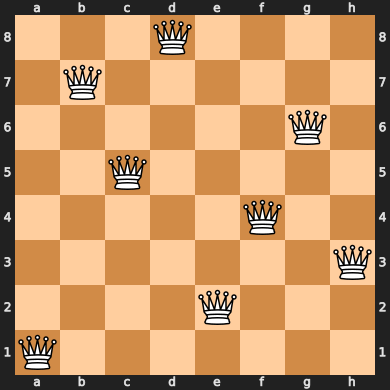

In [ ]:
for sol in prolog.query("n_rainhas(%d, Qs)." % (8)):
  print(sol['Qs'])
  mostrar_tabuleiro(sol['Qs'])
  break

## Sudoku

[Sudoku](https://pt.wikipedia.org/wiki/Sudoku) é um jogo de lógica e raciocínio que consiste em preencher uma matriz 9x9 com números de 1 a 9, atendendo um conjunto de restrições. A matriz é dividida em 9 blocos menores, cada um com 3 linhas e 3 colunas.

O objetivo é garantir que cada linha, cada coluna e cada um dos nove blocos 3x3 que compõem a grade contenham todos os números de 1 a 9, sem repetições.



In [ ]:
# Baixe o arquivo
!gdown 1PVQ-mtkdln5xnTFYySnOB0DyvzI_ZFn3

In [ ]:
prolog.consult('sudoku.pl')


> O seguinte código Prolog é um solver Sudoku.

>
> ```prolog
> :- use_module(library(clpfd)).
>
> sudoku(Rows) :-
>     length(Rows, 9),
>     maplist(same_length(Rows), Rows),
>     append(Rows, Cells), Cells ins 1..9,
>     maplist(all_distinct, Rows),
>     transpose(Rows, Columns), maplist(all_distinct, Columns),
>     Rows = [R1,R2,R3, R4,R5,R6, R7,R8,R9],
>     blocks(R1, R2, R3), blocks(R4, R5, R6), blocks(R7, R8, R9).
>
> blocks([], [], []).
> blocks([A,B,C|T1], [D,E,F|T2], [G,H,I|T3]) :-
>     all_distinct([A,B,C, D,E,F, G,H,I]),
>     blocks(T1, T2, T3).
> ```
>
> **Funcionamento do código:**
>
> 1.  **`:- use_module(library(clpfd)).`**: Carrega a biblioteca `clpfd` para programação lógica com restrições.
> 2.  **`sudoku(Rows)`**: Define a regra principal. O tabuleiro `Rows` deve:
>     * Ter 9 linhas (`length(Rows, 9)`).
>     * Cada linha ter 9 colunas (`maplist(same_length(Rows), Rows)`).
>     * Todas as células conterem números de 1 a 9 (`append(Rows, Cells), Cells ins 1..9`).
>     * Números distintos em cada linha e coluna (`maplist(all_distinct, Rows)`, `transpose(...)`).
>     * Números distintos em cada bloco 3x3 (`blocks(...)`).
> 3.  **`blocks([], [], [])`**: Caso base da regra `blocks`.
> 4.  **`blocks([A,B,C|T1], ...)`**: Regra recursiva para verificar blocos 3x3.
>


In [ ]:
from pyswip import Prolog, Variable

def converter_tabuleiro(tabuleiro):
    """Converte um tabuleiro de Sudoku com zeros em um tabuleiro com variáveis Prolog."""
    tabuleiro_convertido = []
    for linha in tabuleiro:
        linha_convertida = [Variable() if celula == 0 else celula for celula in linha]
        tabuleiro_convertido.append(linha_convertida)
    return tabuleiro_convertido

prolog = Prolog()
prolog.consult("sudoku.pl")

# Tabuleiro inicial com zeros
puzzle = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

# Converte o tabuleiro
puzzle_convertido = converter_tabuleiro(puzzle)

# Converte o tabuleiro Python para o formato Prolog
prolog_puzzle = "[" + ",".join(["[" + ",".join(map(lambda x: str(x) if isinstance(x, int) else "_", row)) + "]" for row in puzzle_convertido]) + "]"

# Executa a consulta Prolog
result = list(prolog.query(f"sudoku(Rows), Rows = {prolog_puzzle}, maplist(label, Rows)"))

# Imprime o resultado
if result:
    solved_puzzle = result[0]["Rows"]
    for row in solved_puzzle:
        print(row)
else:
    print("Sem solução encontrada.")

## Solução com Backtracking

[Backtracking](https://pt.wikipedia.org/wiki/Backtracking) é uma técnica de resolução de problemas que explora todas as possíveis soluções de forma sistemática, retrocedendo (*backtrack*) quando encontra um caminho inválido, até encontrar a solução correta ou esgotar todas as opções.

O código a seguir é uma implementação simples que tenta preencher as células vazias com números válidos. Se chegar a um ponto onde não há números válidos para uma célula, ele "volta" (*backtrack*) e tenta outro número na célula anterior.
Esse processo continua até que o tabuleiro seja completamente preenchido ou até que se determine que não há solução.

In [ ]:
def print_sudoku(board):
    for i in range(9):
        if i % 3 == 0 and i != 0:
            print("- - - - - - - - - - -")
        for j in range(9):
            if j % 3 == 0 and j != 0:
                print("|", end=" ")
            print(board[i][j], end=" ")
        print()

def find_empty(board):
    for i in range(9):
        for j in range(9):
            if board[i][j] == 0:
                return (i, j)  # Retorna a posição (linha, coluna) de uma célula vazia
    return None  # Se não houver células vazias, o Sudoku está resolvido

def is_valid(board, num, pos):
    # Verifica a linha
    for i in range(9):
        if board[pos[0]][i] == num and pos[1] != i:
            return False

    # Verifica a coluna
    for i in range(9):
        if board[i][pos[1]] == num and pos[0] != i:
            return False

    # Verifica o bloco 3x3
    box_x = pos[1] // 3
    box_y = pos[0] // 3

    for i in range(box_y * 3, box_y * 3 + 3):
        for j in range(box_x * 3, box_x * 3 + 3):
            if board[i][j] == num and (i, j) != pos:
                return False

    return True

def solve_sudoku(board):
    find = find_empty(board)
    if not find:
        return True  # Sudoku resolvido
    else:
        row, col = find

    for num in range(1, 10):  # Tenta números de 1 a 9
        if is_valid(board, num, (row, col)):
            board[row][col] = num  # Insere o número se for válido

            if solve_sudoku(board):  # Chama recursivamente
                return True

            board[row][col] = 0  # Backtracking: remove o número se não levar à solução

    return False  # Retorna False se nenhum número for válido

# Exemplo de tabuleiro de Sudoku (0 representa células vazias)
board = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

print("Tabuleiro inicial:")
print_sudoku(board)

if solve_sudoku(board):
    print("\nTabuleiro resolvido:")
    print_sudoku(board)
else:
    print("Não há solução para este Sudoku.")

# Exercícios
1. Escreva um solução para o problemas das $N$-Damas usando backtracking.
2. Implemente um agente para o mundo de wumpus em Prolog.